<a href="https://colab.research.google.com/github/ishitamunshi/world_model_stacking/blob/main/notebooks/combined_cost.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CIS 6280 - Final Combined-Cost Planning Benchmark

**Goal:** Compare the original professor-provided planner against the two strongest individual scoring rules and two combined scoring rules. Pretrained policy, world model, subgoal images, simulator, and all non-scoring planner settings are held fixed.

**Run on:** Google Colab, **Runtime → Change runtime type → A100 GPU (when available) OR L4.**

**Study design:** First 40 entries of `goals/scripted-val100-every80/goals.npz`, policy sampler seed `0`, 16 candidates, `generate=16`, `execute=1`, `tau=0.25`, horizon 1,795. Five methods × 40 scenes = **200 episodes**. This is a **shared development benchmark**, not an untouched final test, because the group has already worked with some of these scenes.

**Methods and scoring:** For predicted latent distances \(D_t=\lVert \hat z_t-g_m\rVert_2^2\),

- `baseline`: \(J=D_H\). Calls the original official `GoalPlanningAgent` without modification.
- `full_025`: \(J=.75D_H+.25\sum_t w_tD_t\), \(w_t=t/\sum_jj\).
- `late4_010`: \(J=.90D_H+.10\operatorname{mean}(D_{H-3:H})\).
- `combined_a`: \(J=.80D_H+.10D_{full}+.10D_{late4}\).
- `combined_b`: \(J=.70D_H+.15D_{full}+.15D_{late4}\).

**Primary measure:** Mean maximum number of connected boxes stacked at any point in an episode, matching the course benchmark. Secondary: final connected box count, success rates for 1–4 boxes, stack loss, grasp rate, ground-fall episodes, goal progress, and inference/runtime. Comparisons are paired by scene, with **10,000-resample bootstrap 95% confidence intervals** and better/worse/same scene counts.

**Fault tolerance:** Every completed episode is saved immediately as one JSON file to Google Drive. After a disconnected runtime, rerun setup and evaluation; successful episode files are skipped. The output folder includes a source-code/protocol fingerprint to avoid accidentally mixing algorithm versions.

**Read the output carefully:** The previous 5-scene Colab numbers were obtained with scene-dependent sampler seeds (and potentially a different GPU). They must **not** be compared numerically with this 40-scene seed-0 benchmark. A100 numerical behavior may also differ slightly from T4.

## 1. Install requirements and verify GPU
Run once per fresh Colab runtime. The first setup may download system packages.

In [1]:
import os, sys, subprocess, importlib.util
os.environ['MUJOCO_GL'] = 'egl'
os.environ['MUJOCO_EGL_DEVICE_ID'] = '0'
os.environ['PYOPENGL_PLATFORM'] = 'egl'
os.environ['HF_HUB_DISABLE_XET'] = '1'
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['MKL_NUM_THREADS'] = '1'

# Official notebook-compatible MuJoCo / EGL dependencies.
env = dict(os.environ, DEBIAN_FRONTEND='noninteractive')
subprocess.run(['apt-get', 'update', '-qq'], check=True, env=env)
subprocess.run(['apt-get', 'install', '-y', '-qq',
                'libegl1', 'libgl1', 'libgles2', 'libglib2.0-0', 'ffmpeg'],
               check=True, env=env)
missing = []
for module, spec in [
    ('mujoco', 'mujoco>=3.3,<4'),
    ('imageio_ffmpeg', 'imageio[ffmpeg]>=2.30'),
    ('huggingface_hub', 'huggingface_hub>=0.26'),
    ('matplotlib', 'matplotlib'),
    ('pandas', 'pandas'),
]:
    if importlib.util.find_spec(module) is None:
        missing.append(spec)
if missing:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                    '--upgrade-strategy', 'only-if-needed', *missing], check=True)

import torch
if not torch.cuda.is_available():
    raise RuntimeError('CUDA GPU unavailable. Choose A100 under Runtime > Change runtime type.')
name = torch.cuda.get_device_name(0)
free_mem, total_mem = torch.cuda.mem_get_info()
print('GPU:', name, '| CUDA:', torch.version.cuda, '| PyTorch:', torch.__version__)
print(f'GPU VRAM: {total_mem/1024**3:.1f} GiB total; {free_mem/1024**3:.1f} GiB free')
if 'A100' not in name:
    print('WARNING: This is not an A100. The benchmark remains valid, but speed/precision may differ.')

GPU: NVIDIA L4 | CUDA: 13.0 | PyTorch: 2.14.1+cu130
GPU VRAM: 22.0 GiB total; 21.8 GiB free


## 2. Download official simulator code and test MuJoCo rendering
This uses the exact code archive supplied for the course's official Colab notebook.

In [2]:
import os, sys, tarfile
from pathlib import Path
from huggingface_hub import hf_hub_download

ROOT = Path('/content/world-model-gym')
marker = ROOT / 'assignment/training/planning/agent.py'
if not marker.exists():
    print('Downloading course code archive...', flush=True)
    archive = hf_hub_download('YongYong/cis6280-stack-world-models-v2',
                              'code/world-model-gym.tar', repo_type='model')
    with tarfile.open(archive) as tar:
        tar.extractall('/content', filter='data')
assert marker.exists(), f'Expected simulator code at {marker}'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
hand_xml = ROOT / 'assets/sharpa/wave_01/right_sharpa_wave/right_sharpa_wave.xml'
if not hand_xml.exists():
    subprocess.run([sys.executable, 'scripts/fetch_assets.py'], check=True)
from assignment.training.data.task import StackTaskEnv, TaskConfig
_demo_env = StackTaskEnv(TaskConfig(target_count=4, horizon=10,
                                     terminate_on_ground=False), 100038)
try:
    _demo_env.reset(('init', 100038))
    _demo_env.env.resolution = 128
    views = list(_demo_env.env.render())
    assert len(views) == 2 and views[0].shape == (128, 128, 3)
    print('PASS: MuJoCo EGL render', views[0].shape, views[1].shape)
finally:
    _demo_env.close()
print('Course code directory:', ROOT)

world-model-gym.tar:   0%|          | 0.00/17.7M [00:00<?, ?B/s]

PASS: MuJoCo EGL render (128, 128, 3) (128, 128, 3)
Course code directory: /content/world-model-gym


## 3. Download policy, world model, and 100-scene goal file
Only these three artifacts are needed; **do not download the training dataset**. The world-model path is supplied explicitly at inference, so the policy checkpoint is not rewritten.

In [3]:
import shutil
import numpy as np
from pathlib import Path
from huggingface_hub import hf_hub_download

CKPT = Path('/content/stack-baseline')
CKPT.mkdir(parents=True, exist_ok=True)
POLICY = CKPT / 'df-smwm-c1-sigma04.pt'
WM = CKPT / 'smwm-c3.pt'
GOALS = CKPT / 'goals-every80.npz'

def fetch(repo, filename, out, repo_type):
    if out.exists() and out.stat().st_size:
        print('Already present:', out.name)
        return
    print('Downloading:', filename, flush=True)
    path = hf_hub_download(repo, filename, repo_type=repo_type)
    shutil.copyfile(path, out)

fetch('YongYong/cis6280-stack-world-models-v2',
      'policy/df-smwm-c1-sigma04/policy.pt', POLICY, 'model')
fetch('YongYong/cis6280-stack-world-models-v2',
      'jepa/smwm-c3/model.pt', WM, 'model')
fetch('YongYong/cis6280-stack-datasets-v2',
      'goals/scripted-val100-every80/goals.npz', GOALS, 'dataset')
with np.load(GOALS) as f:
    VAL_SEEDS = [int(s) for s in f['seeds']]
    print('Scenes available in val100 file:', len(VAL_SEEDS))
    print('First 40 scene IDs:', VAL_SEEDS[:40])
    assert len(VAL_SEEDS) >= 40 and len(set(VAL_SEEDS[:40])) == 40
print('PASS: all checkpoints and goal frames available')

Downloading: policy/df-smwm-c1-sigma04/policy.pt


policy.pt:   0%|          | 0.00/157M [00:00<?, ?B/s]

Downloading: jepa/smwm-c3/model.pt


model.pt:   0%|          | 0.00/73.4M [00:00<?, ?B/s]

Downloading: goals/scripted-val100-every80/goals.npz


goals.npz:   0%|          | 0.00/34.1M [00:00<?, ?B/s]

Scenes available in val100 file: 100
First 40 scene IDs: [100035, 100038, 100057, 100060, 100069, 100072, 100078, 100085, 100087, 100098, 100102, 100137, 100145, 100152, 100164, 100166, 100169, 100175, 100183, 100186, 100187, 100195, 100219, 100221, 100223, 100236, 100246, 100258, 100279, 100287, 100306, 100343, 100349, 100353, 100379, 100395, 100413, 100415, 100434, 100436]
PASS: all checkpoints and goal frames available


## 4. Install the experimental planner (self-contained source)
Creates `cis6280_combined_planner.py` inside the working runtime. It preserves the professor's goal-switching logic and changes **only the trajectory scoring** for alternatives.

In [4]:
from pathlib import Path
EXPERIMENT_DIR = Path('/content/cis6280_combined_benchmark')
EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)
PLANNER_FILE = EXPERIMENT_DIR / 'cis6280_combined_planner.py'
PLANNER_FILE.write_text('"""CIS 6280 combined trajectory scoring planner.\n\nFrozen policy / world model / subgoals. The only experimental variable is the\ncandidate scoring rule; the base class preserves original goal switching.\n"""\nfrom __future__ import annotations\n\nimport numpy as np\nimport torch\n\nfrom assignment.training.data.cache import RAW_ACTION_DIM, STRIDE\nfrom assignment.training.planning.agent import GoalPlanningAgent\n\n# Coefficients sum to 1 for every method. These are prespecified DEVELOPMENT\n# candidates, not optimized/tested outcomes.\nMETHOD_WEIGHTS = {\n    \'baseline\': (1.00, 0.00, 0.00),\n    \'full_025\': (0.75, 0.25, 0.00),\n    \'late4_010\': (0.90, 0.00, 0.10),\n    \'combined_a\': (0.80, 0.10, 0.10),\n    \'combined_b\': (0.70, 0.15, 0.15),\n}\nDEFAULT_METHODS = tuple(METHOD_WEIGHTS)\n\n\ndef candidate_costs(pred: torch.Tensor, goal: torch.Tensor, *,\n                    weights: tuple[float, float, float], late_k: int = 4):\n    """Return candidate costs and component vectors, all [N].\n\n    pred [N, H, D], goal [D]; all distances are squared latent L2.\n    Full-trajectory weights are linear in time (1..H) as in Experiment 1.\n    Late-horizon term averages only the final late_k predicted states.\n    """\n    if pred.ndim != 3 or goal.ndim != 1 or pred.shape[-1] != goal.numel():\n        raise ValueError(\'Expected pred [N,H,D] and goal [D]\')\n    if not 1 <= late_k <= pred.shape[1]:\n        raise ValueError(\'late_k must be from 1 through H\')\n    if len(weights) != 3 or any(w < 0 for w in weights) or abs(sum(weights) - 1) > 1e-6:\n        raise ValueError(\'Nonnegative weights must sum to 1\')\n    distances = (pred.float() - goal.float()).square().sum(-1)  # [N,H]\n    terminal = distances[:, -1]\n    times = torch.arange(1, distances.shape[1] + 1, device=distances.device,\n                         dtype=distances.dtype)\n    times = times / times.sum()\n    full = (distances * times[None, :]).sum(-1)\n    late = distances[:, -late_k:].mean(-1)\n    wt, wf, wl = weights\n    score = wt * terminal + wf * full + wl * late\n    return score, {\'terminal\': terminal, \'full\': full, \'late\': late}\n\n\nclass ScoredGoalPlanningAgent(GoalPlanningAgent):\n    """Original agent and state/subgoal logic, but custom candidate ranking."""\n    def __init__(self, policy_path, device=\'cuda\', *, method=\'combined_a\',\n                 late_k=4, candidates=16, tau=0.25, **kwargs):\n        if method not in METHOD_WEIGHTS:\n            raise ValueError(f\'Unknown method: {method}\')\n        self.method = method\n        self.late_k = int(late_k)\n        super().__init__(policy_path, device=device, candidates=candidates,\n                         tau=tau, **kwargs)\n        self.ranking_changes = 0\n        self.ranking_calls = 0\n\n    def reset(self, goal_frames=None, init_frame=None, seed=None):\n        super().reset(goal_frames=goal_frames, init_frame=init_frame, seed=seed)\n        self.ranking_changes = 0\n        self.ranking_calls = 0\n\n    @torch.no_grad()\n    def step(self, frame):\n        if self.goals is None:\n            raise RuntimeError(\'Call reset(goal_frames, init_frame, seed) before step\')\n        z = self._encode(frame[None])[0]\n        ctx = self.encoder.cfg.context\n        self.frames = (self.frames + [z])[-ctx:]\n        self.history = (self.history + [(z - self.z_mean) / self.z_std])[-self.policy.cfg.context:]\n        goal = self.goals[self.goal_index(z)]\n\n        if not self.queue:\n            pctx = [self.history[0]] * (self.policy.cfg.context - len(self.history)) + self.history\n            n = self.candidates\n            blocks = self.policy.sample(torch.stack(pctx)[None].expand(n, -1, -1),\n                                        self.generate, self.n_steps, self.lag, self.generator)\n            best = 0\n            if n > 1:\n                past = self.executed[len(self.executed) - len(self.frames) + 1:] if len(self.frames) > 1 else []\n                acts = (torch.cat([torch.stack(past)[None].expand(n, -1, -1), blocks], 1)\n                        if past else blocks)\n                with self._autocast():\n                    pred = self.encoder.rollout(\n                        torch.stack(self.frames)[None].expand(n, -1, -1),\n                        self.encoder.action_encoder(acts), self.generate)\n                score, parts = candidate_costs(pred, goal,\n                                               weights=METHOD_WEIGHTS[self.method],\n                                               late_k=self.late_k)\n                self.last_distance = parts[\'terminal\']\n                self.last_score = score\n                best = int(score.argmin())\n                self.ranking_calls += 1\n                self.ranking_changes += int(best != int(parts[\'terminal\'].argmin()))\n\n            raw = np.clip(blocks[best, :self.execute].cpu().numpy() * self.a_std + self.a_mean,\n                          -1, 1)\n            self.queue = list(raw.reshape(-1, STRIDE, RAW_ACTION_DIM))\n        block = self.queue.pop(0)\n        self.executed.append(torch.from_numpy(\n            (block.reshape(-1) - self.a_mean) / self.a_std).to(self.device))\n        return block\n\n\ndef run_mathematical_tests(device=\'cpu\'):\n    """Cheap tests, no checkpoint or simulator required."""\n    torch.manual_seed(9281)\n    z = torch.randn(16, 16, 192, device=device)\n    g = torch.randn(192, device=device)\n    terminal = (z[:, -1].float() - g.float()).square().sum(-1)\n    for name, weights in METHOD_WEIGHTS.items():\n        s, components = candidate_costs(z, g, weights=weights)\n        assert s.shape == (16,)\n        assert torch.isfinite(s).all()\n        if name == \'baseline\':\n            torch.testing.assert_close(s, terminal, atol=0, rtol=0)\n        else:\n            # Verify result directly from defined weights.\n            t, f, l = weights\n            torch.testing.assert_close(s, t*components[\'terminal\'] +\n                                       f*components[\'full\'] + l*components[\'late\'])\n    # Explicit equivalence of independent Experiment 1 & 2 definitions.\n    distances = (z.float() - g.float()).square().sum(-1)\n    timeweights = torch.arange(1, 17, device=device).float()\n    timeweights /= timeweights.sum()\n    full_exp1 = .75 * distances[:, -1] + .25 * (distances * timeweights).sum(1)\n    late_exp2 = .90 * distances[:, -1] + .10 * distances[:, -4:].mean(1)\n    torch.testing.assert_close(candidate_costs(z, g, weights=METHOD_WEIGHTS[\'full_025\'])[0], full_exp1)\n    torch.testing.assert_close(candidate_costs(z, g, weights=METHOD_WEIGHTS[\'late4_010\'])[0], late_exp2)\n    print(\'PASS: baseline terminal cost exactly matches\')\n    print(\'PASS: full alpha=0.25 matches Experiment 1\')\n    print(\'PASS: late-4 alpha=0.10 matches Experiment 2\')\n    print(\'PASS: both combined objectives yield finite [16] candidate scores\')\n', encoding='utf-8')
import sys
if str(EXPERIMENT_DIR) not in sys.path:
    sys.path.insert(0, str(EXPERIMENT_DIR))
print('Planner written:', PLANNER_FILE, '| bytes:', PLANNER_FILE.stat().st_size)

Planner written: /content/cis6280_combined_benchmark/cis6280_combined_planner.py | bytes: 6735


## 5. Mathematical verification (no simulation)
Check exact baseline equivalence, correct reproduction of Experiments 1 and 2, and finite scores for the combined planners.

In [5]:
import importlib
import cis6280_combined_planner as cp
importlib.reload(cp)
cp.run_mathematical_tests(device='cuda')
print('\nCost functions:')
for name, (w_terminal, w_full, w_late) in cp.METHOD_WEIGHTS.items():
    print(f'  {name:<12} = {w_terminal:.2f} terminal + '
          f'{w_full:.2f} full + {w_late:.2f} late-4')
assert set(cp.DEFAULT_METHODS) == {
    'baseline','full_025','late4_010','combined_a','combined_b'}
print('PASS: Method configuration is complete')

PASS: baseline terminal cost exactly matches
PASS: full alpha=0.25 matches Experiment 1
PASS: late-4 alpha=0.10 matches Experiment 2
PASS: both combined objectives yield finite [16] candidate scores

Cost functions:
  baseline     = 1.00 terminal + 0.00 full + 0.00 late-4
  full_025     = 0.75 terminal + 0.25 full + 0.00 late-4
  late4_010    = 0.90 terminal + 0.00 full + 0.10 late-4
  combined_a   = 0.80 terminal + 0.10 full + 0.10 late-4
  combined_b   = 0.70 terminal + 0.15 full + 0.15 late-4
PASS: Method configuration is complete


## 6. Install parallel evaluator and configure Google Drive
The simulator and model are loaded separately in each **spawned worker process**. This avoids CUDA multiprocessing problems in notebook-local functions. A **40 GB A100 defaults to 3 workers**; an **80 GB A100 defaults to 6**. If GPU memory errors occur, lower `WORKERS` to 2 and rerun; completed episodes are retained.

In [6]:
from pathlib import Path
RUNNER_FILE = EXPERIMENT_DIR / 'cis6280_parallel_benchmark.py'
RUNNER_FILE.write_text('"""Restartable parallel A100 benchmark for CIS 6280 planning.\n\nRun as a REAL Python script, not an interactive notebook cell: spawn-based\nCUDA multiprocessing cannot reliably import a notebook-local function.\n"""\nfrom __future__ import annotations\n\nimport argparse\nfrom concurrent.futures import ProcessPoolExecutor, as_completed\nfrom datetime import datetime, timezone\nimport json\nimport multiprocessing as mp\nimport os\nfrom pathlib import Path\nimport sys\nimport time\nimport traceback\n\nMETHODS = (\'baseline\', \'full_025\', \'late4_010\', \'combined_a\', \'combined_b\')\n_WORKER_AGENT = None\n_WORKER_METHOD = None\n_WORKER_GOALS = None\n_WORKER_GOAL_PATH = None\n_WORKER_ROWS = None\n\n\ndef init_worker(root):\n    """Set EGL/CUDA env and CPU threads inside a spawned child."""\n    os.environ[\'MUJOCO_GL\'] = \'egl\'\n    os.environ[\'MUJOCO_EGL_DEVICE_ID\'] = \'0\'\n    os.environ[\'PYOPENGL_PLATFORM\'] = \'egl\'\n    os.environ[\'OMP_NUM_THREADS\'] = \'1\'\n    os.environ[\'MKL_NUM_THREADS\'] = \'1\'\n    os.chdir(root)\n    if root not in sys.path:\n        sys.path.insert(0, root)\n    import torch\n    torch.set_num_threads(1)\n\n\ndef _get_agent(job):\n    global _WORKER_AGENT, _WORKER_METHOD\n    import torch\n    from assignment.training.planning.agent import GoalPlanningAgent\n    from cis6280_combined_planner import ScoredGoalPlanningAgent\n    method = job[\'method\']\n    if _WORKER_AGENT is not None and _WORKER_METHOD == method:\n        return _WORKER_AGENT\n    if _WORKER_AGENT is not None:\n        del _WORKER_AGENT\n        _WORKER_AGENT = None\n        import gc\n        gc.collect()\n        torch.cuda.empty_cache()\n\n    kwargs = dict(device=\'cuda\', candidates=16, tau=0.25, generate=16,\n                  execute=1, world_model=job[\'world_model\'])\n    if method == \'baseline\':\n        _WORKER_AGENT = GoalPlanningAgent(job[\'policy\'], **kwargs)\n    else:\n        _WORKER_AGENT = ScoredGoalPlanningAgent(job[\'policy\'], method=method,\n                                                 late_k=4, **kwargs)\n    _WORKER_METHOD = method\n    return _WORKER_AGENT\n\n\ndef _get_goals(path, seed):\n    global _WORKER_GOALS, _WORKER_GOAL_PATH, _WORKER_ROWS\n    import numpy as np\n    if _WORKER_GOALS is None or _WORKER_GOAL_PATH != path:\n        with np.load(path) as f:\n            _WORKER_GOALS = {key: f[key] for key in f.files}\n        _WORKER_GOAL_PATH = path\n        _WORKER_ROWS = {int(s): i for i, s in enumerate(_WORKER_GOALS[\'seeds\'])}\n    if seed not in _WORKER_ROWS:\n        raise KeyError(f\'Missing goal frames for scene {seed}\')\n    idx = _WORKER_ROWS[seed]\n    n = int(_WORKER_GOALS[\'sub_count\'][idx])\n    return (_WORKER_GOALS[\'sub_frames\'][idx, :n],\n            _WORKER_GOALS[\'init_frames\'][idx])\n\n\ndef evaluate_episode(job):\n    """Single 1795-step episode, mirroring official evaluate.py conventions."""\n    import numpy as np\n    from assignment.training.data.cache import STRIDE\n    from assignment.training.data.signals import row_hand_parts, row_lifted\n    from assignment.training.data.task import StackTaskEnv, TaskConfig\n\n    method = job[\'method\']\n    scene = int(job[\'scene_seed\'])\n    sample_seed = int(job[\'sample_seed\'])\n    episode_seed = scene + 1_000_000 * sample_seed  # OFFICIAL seeding convention\n    goals, init = _get_goals(job[\'goals\'], scene)\n    agent = _get_agent(job)\n    agent.reset(goals, init, episode_seed)\n    env = StackTaskEnv(TaskConfig(target_count=4, horizon=1795,\n                                   terminate_on_ground=False), scene)\n    peak = 0\n    first_placement = None\n    ground_falls = grasp_steps = lifted_steps = 0\n    stage_steps = []\n    final_info = {}\n    agent_seconds = 0.0\n    steps = 0\n    was_success = False\n    longest_stall = stall_streak = 0\n    previous_index = None\n    goal_trace = []\n    total_started = time.perf_counter()\n    try:\n        env.reset((\'init\', scene))\n        env.env.resolution = 128\n        for step in range(1795):\n            if step % STRIDE == 0:\n                rgb = np.concatenate(list(env.env.render()), axis=1)\n                t0 = time.perf_counter()\n                block = agent.step(rgb)\n                agent_seconds += time.perf_counter() - t0\n                current_index = int(agent.index)\n                if current_index == previous_index:\n                    stall_streak += 1\n                else:\n                    stall_streak = 1\n                previous_index = current_index\n                longest_stall = max(longest_stall, stall_streak)\n                if step % 100 == 0:\n                    goal_trace.append([int(step), current_index])\n\n            _, _, terminated, truncated, info = env.step(block[step % STRIDE])\n            final_info = info\n            steps = step + 1\n            placed = int(info[\'placed\'])\n            while len(stage_steps) < placed:\n                stage_steps.append(steps)\n            ground_falls += int(info[\'ground\'])\n            row = env.env.history[-1]\n            grasp_steps += int(bool((row_hand_parts(row)[0] >= 2).any()))\n            lifted_steps += int(bool((row_lifted(row) & ~env.members).any()))\n            if first_placement is None and placed > peak:\n                first_placement = steps\n            peak = max(peak, placed)\n            if terminated or truncated:\n                was_success = bool(info[\'success\'])\n                break\n    finally:\n        env.close()\n\n    elapsed = time.perf_counter() - total_started\n    ranking_calls = int(getattr(agent, \'ranking_calls\', 0))\n    ranking_changes = int(getattr(agent, \'ranking_changes\', 0))\n    return dict(\n        status=\'ok\', method=method, scene_seed=scene, sample_seed=sample_seed,\n        episode_seed=episode_seed, n_goals=int(len(goals)),\n        candidates=16, generate=16, execute=1, tau=0.25, horizon=1795,\n        max_placed=int(peak), final_placed=int(final_info.get(\'placed\', 0)),\n        final_count=int(final_info.get(\'count\', 0)),\n        stack_loss=int(peak - final_info.get(\'placed\', 0)),\n        first_placement_step=first_placement, ground_falls=int(ground_falls),\n        grasp_steps=int(grasp_steps), lifted_steps=int(lifted_steps),\n        success=bool(was_success), steps=int(steps), stage_steps=stage_steps,\n        goal_index=int(agent.index), longest_stall_replans=int(longest_stall),\n        goal_trace=goal_trace, ranking_calls=ranking_calls,\n        candidate_change_rate=(ranking_changes/ranking_calls if ranking_calls else None),\n        agent_s=round(agent_seconds, 3), seconds=round(elapsed, 3))\n\n\ndef episode_file(out_dir, method, seed, sample_seed):\n    return Path(out_dir) / \'episodes\' / method / f\'scene_{seed}_sample_{sample_seed}.json\'\n\n\ndef is_complete(path, protocol_id):\n    if not path.exists():\n        return False\n    try:\n        data = json.loads(path.read_text())\n        return data.get(\'status\') == \'ok\' and data.get(\'protocol_id\') == protocol_id\n    except (OSError, ValueError):\n        return False\n\n\ndef atomic_save(path, obj):\n    path.parent.mkdir(parents=True, exist_ok=True)\n    temp = path.with_suffix(path.suffix + f\'.tmp{os.getpid()}\')\n    temp.write_text(json.dumps(obj, indent=2))\n    os.replace(temp, path)\n\n\ndef main():\n    p = argparse.ArgumentParser(description=__doc__)\n    p.add_argument(\'--root\', required=True)\n    p.add_argument(\'--policy\', required=True)\n    p.add_argument(\'--world-model\', required=True)\n    p.add_argument(\'--goals\', required=True)\n    p.add_argument(\'--out-dir\', required=True)\n    p.add_argument(\'--protocol-id\', required=True)\n    p.add_argument(\'--methods\', default=\',\'.join(METHODS))\n    p.add_argument(\'--scene-offset\', type=int, default=0)\n    p.add_argument(\'--scene-count\', type=int, default=40)\n    p.add_argument(\'--sample-seeds\', default=\'0\')\n    p.add_argument(\'--workers\', type=int, default=3)\n    p.add_argument(\'--dry-run\', action=\'store_true\')\n    args = p.parse_args()\n\n    methods = [m.strip() for m in args.methods.split(\',\') if m.strip()]\n    if not methods or any(m not in METHODS for m in methods):\n        raise ValueError(f\'Invalid methods: {methods}; valid: {METHODS}\')\n    if len(methods) != len(set(methods)):\n        raise ValueError(\'Duplicate methods in --methods\')\n    sample_seeds = [int(s) for s in args.sample_seeds.split(\',\')]\n    if args.workers < 1:\n        raise ValueError(\'--workers must be >=1\')\n    for f in (args.policy, args.world_model, args.goals):\n        if not Path(f).is_file():\n            raise FileNotFoundError(f)\n\n    # Use supplied val100 file order. The first 40 are the teammate\'s 40 scenes.\n    import numpy as np\n    with np.load(args.goals) as f:\n        all_seeds = [int(s) for s in f[\'seeds\']]\n    seeds = all_seeds[args.scene_offset:args.scene_offset + args.scene_count]\n    if len(seeds) != args.scene_count:\n        raise ValueError(\'Requested more scenes than the goals file contains\')\n    if len(seeds) != len(set(seeds)):\n        raise ValueError(\'Duplicate scenes in selected slice\')\n    print(f\'Scenes: {len(seeds)} (file indices {args.scene_offset}..\'\n          f\'{args.scene_offset + args.scene_count - 1}; {seeds[0]}..{seeds[-1]})\', flush=True)\n    print(f\'Methods: {methods}, sampler seeds: {sample_seeds}, workers: {args.workers}\', flush=True)\n    out_dir = Path(args.out_dir)\n    manifest_path = out_dir / \'manifest.json\'\n    manifest = dict(\n        protocol_id=args.protocol_id, scenes=seeds, scene_offset=args.scene_offset,\n        methods=methods, sample_seeds=sample_seeds, workers=args.workers,\n        policy=str(Path(args.policy).resolve()), world_model=str(Path(args.world_model).resolve()),\n        goals=str(Path(args.goals).resolve()), fixed_config=dict(candidates=16,\n        tau=0.25, generate=16, execute=1, horizon=1795, target_count=4,\n        resolution=128, terminate_on_ground=False))\n    if args.dry_run:\n        print(json.dumps(manifest, indent=2), flush=True)\n        return\n    if manifest_path.exists():\n        old = json.loads(manifest_path.read_text())\n        old_seeds = old.get(\'scenes\', [])\n        n_shared = min(len(seeds), len(old_seeds))\n        if old.get(\'protocol_id\') != args.protocol_id or old_seeds[:n_shared] != seeds[:n_shared]:\n            # Allow the 1-scene preflight to grow into 40 scenes, but never\n            # reuse results for a different set of scenes or scorer version.\n            raise RuntimeError(\'Output manifest conflicts with requested scenes/protocol. Use a new out-dir.\')\n    # Preserve the manifest for the full run once it expands from preflight.\n    if not manifest_path.exists() or len(json.loads(manifest_path.read_text())[\'scenes\']) < len(seeds):\n        atomic_save(manifest_path, manifest)\n\n    ctx = mp.get_context(\'spawn\')\n    jobs_total = len(seeds) * len(methods) * len(sample_seeds)\n    completed_in_this_call = 0\n    skipped = 0\n    wall_start = time.perf_counter()\n    root = str(Path(args.root).resolve())\n    with ProcessPoolExecutor(max_workers=args.workers, mp_context=ctx,\n                             initializer=init_worker, initargs=(root,)) as pool:\n        # Method-major scheduling keeps one loaded policy+WM per worker for 40 scenes.\n        for method in methods:\n            jobs = []\n            for sample_seed in sample_seeds:\n                for scene in seeds:\n                    path = episode_file(out_dir, method, scene, sample_seed)\n                    if is_complete(path, args.protocol_id):\n                        skipped += 1\n                        continue\n                    jobs.append(dict(method=method, sample_seed=sample_seed,\n                                     scene_seed=scene, goals=str(Path(args.goals).resolve()),\n                                     policy=str(Path(args.policy).resolve()),\n                                     world_model=str(Path(args.world_model).resolve())))\n            print(f\'\\n== {method}: {len(jobs)} pending episodes ==\', flush=True)\n            futures = {pool.submit(evaluate_episode, job): job for job in jobs}\n            for future in as_completed(futures):\n                job = futures[future]\n                try:\n                    result = future.result()\n                except Exception:\n                    print(\'FAILED job \' + repr(job) + \'\\n\' + traceback.format_exc(), flush=True)\n                    raise RuntimeError(\'Aborting; completed jobs are already saved. \'\n                                       \'If OOM, reconnect and reduce workers.\')\n                result[\'protocol_id\'] = args.protocol_id\n                path = episode_file(out_dir, method, job[\'scene_seed\'], job[\'sample_seed\'])\n                atomic_save(path, result)\n                completed_in_this_call += 1\n                print(f"Saved [{completed_in_this_call} new / {jobs_total} total] "\n                      f"{method} scene={result[\'scene_seed\']} sample={result[\'sample_seed\']} "\n                      f"peak={result[\'max_placed\']} final={result[\'final_placed\']} "\n                      f"wall_s={result[\'seconds\']}", flush=True)\n    print(f\'\\nDONE. New episodes: {completed_in_this_call}; skipped: {skipped}; \'\n          f\'wall_s: {time.perf_counter() - wall_start:.1f}; out: {out_dir}\', flush=True)\n\n\nif __name__ == \'__main__\':\n    main()\n', encoding='utf-8')

from google.colab import drive
drive.mount('/content/drive')
import hashlib, json
import torch

METHODS = ['baseline', 'full_025', 'late4_010', 'combined_a', 'combined_b']
SCENE_COUNT = 40
SCENE_OFFSET = 0  # first 40 entries in val100, matching teammate
SAMPLE_SEEDS = [0]  # official episode seed = scene + 1_000_000 * sampler_seed
TOTAL_VRAM_GIB = torch.cuda.get_device_properties(0).total_memory / 1024**3
WORKERS = 2
#if TOTAL_VRAM_GIB >= 70 else 3
# You can override WORKERS manually, e.g. WORKERS = 2, if CUDA out-of-memory occurs.

PROTOCOL_CONFIG = dict(methods=METHODS, scene_count=SCENE_COUNT,
                       scene_offset=SCENE_OFFSET, sample_seeds=SAMPLE_SEEDS,
                       candidates=16, tau=0.25, generate=16, execute=1,
                       horizon=1795, policy_size=POLICY.stat().st_size,
                       world_model_size=WM.stat().st_size,
                       goals_size=GOALS.stat().st_size)
SOURCE_SIGNATURE = hashlib.sha256(
    PLANNER_FILE.read_bytes() + RUNNER_FILE.read_bytes() +
    json.dumps(PROTOCOL_CONFIG, sort_keys=True).encode()
).hexdigest()[:12]
DRIVE_ROOT = Path('/content/drive/MyDrive/world_model_stacking')
RUN_DIR = DRIVE_ROOT / 'combined_benchmark' / f'first40_seed0_{SOURCE_SIGNATURE}'
RUN_DIR.mkdir(parents=True, exist_ok=True)

BASE_COMMAND = [sys.executable, '-u', str(RUNNER_FILE),
    '--root', str(ROOT), '--policy', str(POLICY),
    '--world-model', str(WM), '--goals', str(GOALS),
    '--out-dir', str(RUN_DIR), '--protocol-id', SOURCE_SIGNATURE]

print('GPU:', torch.cuda.get_device_name(0))
print('Parallel workers:', WORKERS)
print('Scene IDs:', VAL_SEEDS[SCENE_OFFSET:SCENE_OFFSET+SCENE_COUNT])
print('Methods:', METHODS)
print('Total planned episodes:', SCENE_COUNT*len(METHODS)*len(SAMPLE_SEEDS))
print('Drive output directory:', RUN_DIR)
print('Protocol/source signature:', SOURCE_SIGNATURE)
# Confirm run configuration without starting expensive inference.
subprocess.run(BASE_COMMAND + ['--scene-count', str(SCENE_COUNT),
    '--methods', ','.join(METHODS), '--sample-seeds', '0',
    '--workers', str(WORKERS), '--dry-run'], cwd=ROOT, check=True)

Mounted at /content/drive
GPU: NVIDIA L4
Parallel workers: 2
Scene IDs: [100035, 100038, 100057, 100060, 100069, 100072, 100078, 100085, 100087, 100098, 100102, 100137, 100145, 100152, 100164, 100166, 100169, 100175, 100183, 100186, 100187, 100195, 100219, 100221, 100223, 100236, 100246, 100258, 100279, 100287, 100306, 100343, 100349, 100353, 100379, 100395, 100413, 100415, 100434, 100436]
Methods: ['baseline', 'full_025', 'late4_010', 'combined_a', 'combined_b']
Total planned episodes: 200
Drive output directory: /content/drive/MyDrive/world_model_stacking/combined_benchmark/first40_seed0_1aba52fda372
Protocol/source signature: 1aba52fda372


CompletedProcess(args=['/usr/bin/python3', '-u', '/content/cis6280_combined_benchmark/cis6280_parallel_benchmark.py', '--root', '/content/world-model-gym', '--policy', '/content/stack-baseline/df-smwm-c1-sigma04.pt', '--world-model', '/content/stack-baseline/smwm-c3.pt', '--goals', '/content/stack-baseline/goals-every80.npz', '--out-dir', '/content/drive/MyDrive/world_model_stacking/combined_benchmark/first40_seed0_1aba52fda372', '--protocol-id', '1aba52fda372', '--scene-count', '40', '--methods', 'baseline,full_025,late4_010,combined_a,combined_b', '--sample-seeds', '0', '--workers', '2', '--dry-run'], returncode=0)

## 7. Preflight: 1 scene × 2 planners
**Run this before the FULL batch.** Tests model loading, CUDA multiprocess workers, MuJoCo EGL, and Google Drive output. It runs baseline and Combined A on the **same scene and sampler seed**. Completed preflight episodes are reused automatically by Cell 8.

In [7]:
print('Running preflight: scene 1, original baseline and combined A, 2 spawned workers.')
preflight_command = BASE_COMMAND + [
    '--scene-count', '1', '--scene-offset', '0',
    '--methods', 'baseline,combined_a',
    '--sample-seeds', '0', '--workers', '2'
]
subprocess.run(preflight_command, cwd=ROOT, check=True)
import json
for m in ['baseline','combined_a']:
    p = RUN_DIR / 'episodes' / m / f'scene_{VAL_SEEDS[0]}_sample_0.json'
    r = json.loads(p.read_text())
    assert r['status'] == 'ok' and r['steps'] > 0
    print('PASS:', m, 'peak=', r['max_placed'],
          'final=', r['final_placed'], 'steps=', r['steps'])
print('PASS: CUDA parallel runner and episode saving verified. Proceed to Cell 8.')

Running preflight: scene 1, original baseline and combined A, 2 spawned workers.
PASS: baseline peak= 2 final= 2 steps= 1795
PASS: combined_a peak= 1 final= 1 steps= 1795
PASS: CUDA parallel runner and episode saving verified. Proceed to Cell 8.


## 8. Full 40-scene parallel benchmark (long-running)
**Only start after Cell 7 passes.** All five methods are evaluated on the same scenes, with **sampler seed 0** and the identical simulator settings. Every finished episode is saved independently. If interrupted, reconnect and rerun Cells 1–6, then Cell 8; it skips completed JSON files.

In [8]:
print('Starting full 40-scene paired benchmark.')
print('Output:', RUN_DIR)
full_command = BASE_COMMAND + [
    '--scene-count', str(SCENE_COUNT),
    '--scene-offset', str(SCENE_OFFSET),
    '--methods', ','.join(METHODS),
    '--sample-seeds', ','.join(map(str, SAMPLE_SEEDS)),
    '--workers', str(WORKERS)
]
# The external Python script can safely use multiprocessing spawn.
subprocess.run(full_command, cwd=ROOT, check=True)
print('All requested episodes complete. Run Cell 9 for analysis.')

Starting full 40-scene paired benchmark.
Output: /content/drive/MyDrive/world_model_stacking/combined_benchmark/first40_seed0_1aba52fda372
All requested episodes complete. Run Cell 9 for analysis.


## 9. Analyze, compare, bootstrap confidence intervals, and save figures
Reads only episode JSONs from this notebook's fingerprinted output folder. For a final 40-scene table, all five methods must have completed on the same 40 scenes. If the batch stopped early, this cell provides a **clearly labeled partial paired summary** instead of silently comparing unequal samples. Outputs CSV, a Markdown report, and three plots.

Successful episode files: 200 / 200
FINAL: 40 complete paired scene+sampler episodes.

TABLE LIKE TEAMMATE REPORT:


,n,mean_boxes,ge1,ge2,ge3,ge4,grasp,mean_final,mean_diff,ci_low,ci_high,better,worse,same
method,,,,,,,,,,,,,,
baseline,40,1.100,80.0,22.5,5.0,2.5,100.0,1.025,0.000,NaN,NaN,0,0,40
full_025,40,1.275,87.5,30.0,10.0,0.0,100.0,1.125,0.175,-0.175,0.525,13,7,20
late4_010,40,1.200,85.0,30.0,2.5,2.5,100.0,1.025,0.100,-0.150,0.375,10,6,24
combined_a,40,1.200,85.0,27.5,7.5,0.0,100.0,1.100,0.100,-0.225,0.400,11,8,21
combined_b,40,0.900,67.5,17.5,5.0,0.0,100.0,0.750,-0.200,-0.500,0.100,6,13,21



OTHER DIAGNOSTICS:


,mean_stack_loss,ground_fall_rate,mean_final_goal_index,mean_longest_stall_replans,mean_candidate_change_pct,mean_agent_s,mean_wall_s
method,,,,,,,
baseline,0.075,0.0,4.575,238.925,NaN,58.640,209.962
full_025,0.150,0.0,6.125,217.075,10.912,59.513,212.057
late4_010,0.175,2.5,5.025,245.825,3.092,60.897,215.932
combined_a,0.100,0.0,5.100,235.600,7.075,59.066,212.093
combined_b,0.150,2.5,4.775,255.675,10.376,59.144,211.679


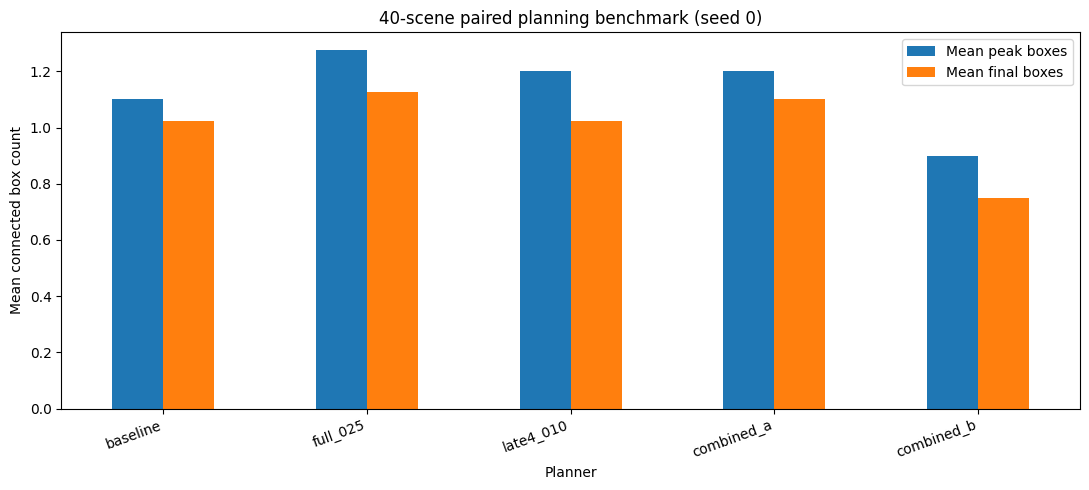

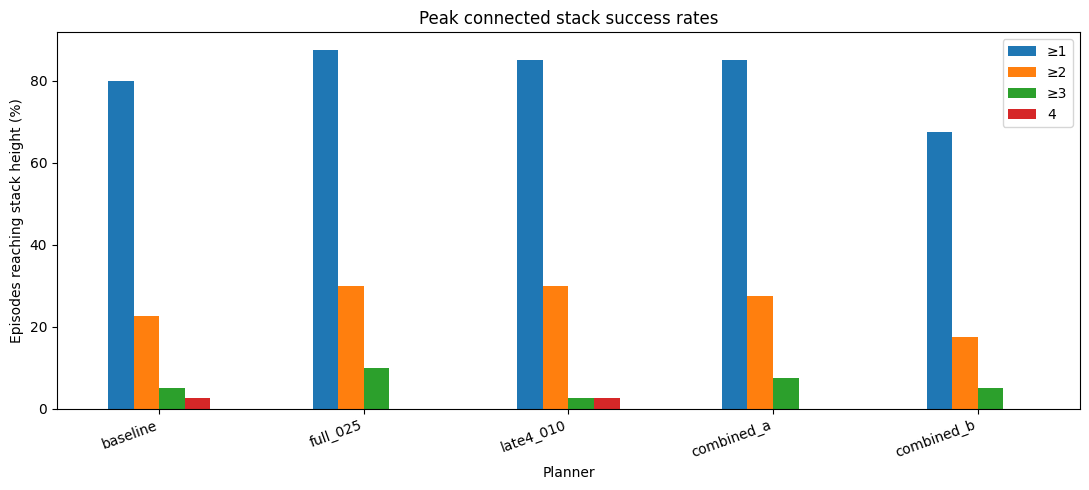

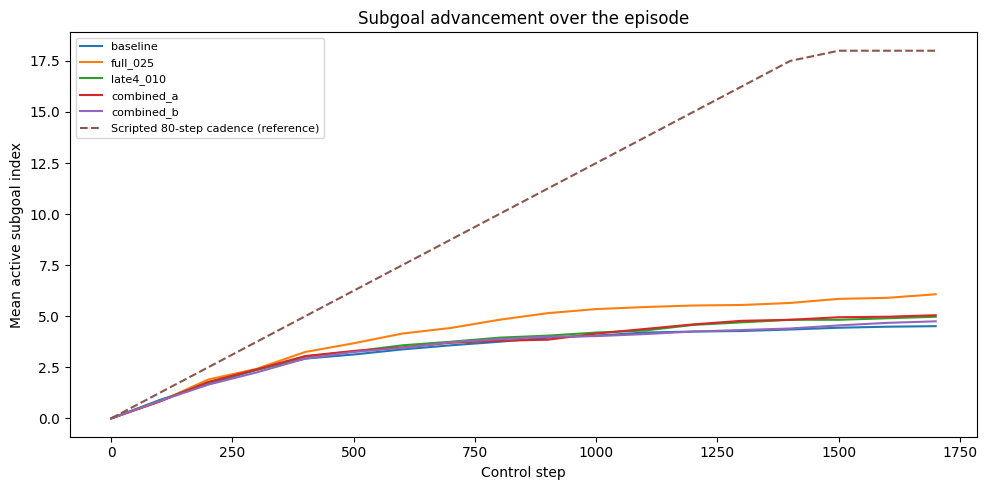

Saved CSVs, Markdown report, and figures in: /content/drive/MyDrive/world_model_stacking/combined_benchmark/first40_seed0_1aba52fda372/reports
PASS: all 40 scenes are fully paired across all five methods.


In [9]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REPORT_DIR = RUN_DIR / 'reports'
REPORT_DIR.mkdir(parents=True, exist_ok=True)
expected_seeds = VAL_SEEDS[SCENE_OFFSET:SCENE_OFFSET + SCENE_COUNT]
rows = []
missing = []
for sample_seed in SAMPLE_SEEDS:
    for seed in expected_seeds:
        for method in METHODS:
            p = RUN_DIR / 'episodes' / method / f'scene_{seed}_sample_{sample_seed}.json'
            if not p.exists():
                missing.append((seed, sample_seed, method))
                continue
            r = json.loads(p.read_text())
            if r.get('status') != 'ok' or r.get('protocol_id') != SOURCE_SIGNATURE:
                missing.append((seed, sample_seed, method))
                continue
            rows.append(r)
print(f'Successful episode files: {len(rows)} / {len(expected_seeds)*len(SAMPLE_SEEDS)*len(METHODS)}')
if missing:
    print('MISSING:', len(missing), 'episodes. First 10:', missing[:10])
if not rows:
    raise RuntimeError('No completed episode files. Run Cell 7 then Cell 8.')

data = pd.DataFrame(rows).drop_duplicates(['scene_seed','sample_seed','method'])
# Only fully matched scene+sample pairs are included in the comparison.
counts = data.groupby(['scene_seed','sample_seed'])['method'].nunique()
complete_keys = counts[counts == len(METHODS)].index
paired = data.set_index(['scene_seed','sample_seed']).loc[complete_keys].reset_index() if len(complete_keys) else pd.DataFrame()
if paired.empty:
    raise RuntimeError('No complete paired scene+sampler tuples. Finish more runs.')
N = len(complete_keys)
IS_COMPLETE = N == len(expected_seeds)*len(SAMPLE_SEEDS)
print(('FINAL' if IS_COMPLETE else 'PARTIAL / NOT FINAL') +
      f': {N} complete paired scene+sampler episodes.')

# Keep precision full in CSV; round only for display.
summary_rows = []
for method in METHODS:
    d = paired.loc[paired.method == method]
    peak = d['max_placed'].to_numpy()
    summary_rows.append(dict(
        method=method, n=len(d), mean_boxes=float(peak.mean()),
        ge1=float((peak >= 1).mean()*100), ge2=float((peak >= 2).mean()*100),
        ge3=float((peak >= 3).mean()*100), ge4=float((peak >= 4).mean()*100),
        grasp=float((d.grasp_steps > 0).mean()*100),
        mean_final=float(d.final_placed.mean()),
        mean_stack_loss=float(d.stack_loss.mean()),
        ground_fall_rate=float((d.ground_falls > 0).mean()*100),
        mean_final_goal_index=float(d.goal_index.mean()),
        mean_longest_stall_replans=float(d.longest_stall_replans.mean()),
        mean_agent_s=float(d.agent_s.mean()),
        mean_wall_s=float(d.seconds.mean()),
        mean_candidate_change_pct=float(d.candidate_change_rate.dropna().mean()*100)
            if d.candidate_change_rate.notna().any() else float('nan')
    ))
summary = pd.DataFrame(summary_rows).set_index('method').loc[METHODS]

# Paired bootstrap resamples *scene+sampler tuples*, preserving method pairing.
peak_wide = paired.pivot(index=['scene_seed','sample_seed'],
                          columns='method', values='max_placed')[METHODS]
B = 10_000
rng = np.random.default_rng(20261120)
comparisons = []
for method in METHODS:
    if method == 'baseline':
        comparisons.append(dict(method=method, mean_diff=0.0,
             ci_low=float('nan'), ci_high=float('nan'), better=0, worse=0, same=N))
        continue
    diff = (peak_wide[method] - peak_wide['baseline']).to_numpy(dtype=float)
    boot_idx = rng.integers(0, len(diff), size=(B, len(diff)))
    boot_means = diff[boot_idx].mean(axis=1)
    low, high = np.percentile(boot_means, [2.5, 97.5])
    comparisons.append(dict(method=method, mean_diff=float(diff.mean()),
        ci_low=float(low), ci_high=float(high),
        better=int((diff > 0).sum()), worse=int((diff < 0).sum()),
        same=int((diff == 0).sum())))
comparison = pd.DataFrame(comparisons).set_index('method').loc[METHODS]
combined_table = summary.join(comparison)

print('\nTABLE LIKE TEAMMATE REPORT:')
show = combined_table[['n','mean_boxes','ge1','ge2','ge3','ge4','grasp',
    'mean_final','mean_diff','ci_low','ci_high','better','worse','same']].copy()
display(show.round(3))
print('\nOTHER DIAGNOSTICS:')
display(combined_table[['mean_stack_loss','ground_fall_rate',
    'mean_final_goal_index','mean_longest_stall_replans',
    'mean_candidate_change_pct','mean_agent_s','mean_wall_s']].round(3))

# Save exact run-level results and both aggregate tables.
paired.to_csv(REPORT_DIR/'all_paired_episodes.csv', index=False)
combined_table.to_csv(REPORT_DIR/'comparison_summary.csv')
peak_wide.to_csv(REPORT_DIR/'paired_scene_peak_matrix.csv')

# Plot 1: primary & final results.
ax = combined_table[['mean_boxes','mean_final']].rename(columns={
    'mean_boxes':'Mean peak boxes','mean_final':'Mean final boxes'}).plot.bar(figsize=(11,5))
ax.set_xlabel('Planner'); ax.set_ylabel('Mean connected box count')
ax.set_title(f'{"40-scene" if IS_COMPLETE else "PARTIAL"} paired planning benchmark (seed 0)')
plt.xticks(rotation=20,ha='right'); plt.tight_layout()
plt.savefig(REPORT_DIR/'mean_peak_final.png',dpi=170)
plt.show()

# Plot 2: success rates.
ax = combined_table[['ge1','ge2','ge3','ge4']].rename(columns={
    'ge1':'≥1','ge2':'≥2','ge3':'≥3','ge4':'4'}).plot.bar(figsize=(11,5))
ax.set_xlabel('Planner'); ax.set_ylabel('Episodes reaching stack height (%)')
ax.set_title('Peak connected stack success rates')
plt.xticks(rotation=20,ha='right'); plt.tight_layout()
plt.savefig(REPORT_DIR/'success_rates.png',dpi=170)
plt.show()

# Plot 3: goal-index progress over time, same diagnostic as teammate.
trace_records = []
for r in rows:
    if (int(r['scene_seed']), int(r['sample_seed'])) not in set(complete_keys):
        continue
    for step, index in r.get('goal_trace', []):
        trace_records.append(dict(method=r['method'], step=step, goal_index=index))
if trace_records:
    trace_df = pd.DataFrame(trace_records)
    plt.figure(figsize=(10,5))
    for method in METHODS:
        g = trace_df[trace_df.method == method].groupby('step')['goal_index'].mean()
        plt.plot(g.index,g.values,label=method)
    plt.plot(np.arange(0,1800,100), np.minimum(np.arange(0,1800,100)/80,18),
             '--',label='Scripted 80-step cadence (reference)')
    plt.xlabel('Control step'); plt.ylabel('Mean active subgoal index')
    plt.title('Subgoal advancement over the episode')
    plt.legend(fontsize=8); plt.tight_layout()
    plt.savefig(REPORT_DIR/'subgoal_progress.png',dpi=170)
    plt.show()

# Write a shareable plain Markdown report.
lines = [
    '# Combined-Cost Planning: 40-Scene Benchmark', '',
    f'**Status:** {"Complete 40-scene paired evaluation" if IS_COMPLETE else "Partial paired evaluation, do not cite as final"}',
    f'**Paired scene/sampler tuples:** {N} / {len(expected_seeds)*len(SAMPLE_SEEDS)}',
    f'**Sampler seeds:** {SAMPLE_SEEDS}',
    f'**Protocol/code fingerprint:** `{SOURCE_SIGNATURE}`',
    '**Frozen components:** pretrained policy, world model, original subgoal manager,',
    '16 candidates, generate=16, execute=1, tau=0.25, horizon=1795.', '',
    '| Method | Mean peak | ≥1 % | ≥2 % | ≥3 % | 4 % | Mean final | Δ vs baseline | 95% bootstrap CI | Better/Worse/Same |',
    '|---|---:|---:|---:|---:|---:|---:|---:|---|---|',
]
for method, r in combined_table.iterrows():
    ci = '—' if method == 'baseline' else f'[{r.ci_low:+.3f}, {r.ci_high:+.3f}]'
    lines.append(f'| {method} | {r.mean_boxes:.3f} | {r.ge1:.1f} | {r.ge2:.1f} | {r.ge3:.1f} | '
                 f'{r.ge4:.1f} | {r.mean_final:.3f} | {r.mean_diff:+.3f} | {ci} | '
                 f'{int(r.better)}/{int(r.worse)}/{int(r.same)} |')
lines += ['', '## Interpretation notes',
          '- Bootstrap confidence intervals are paired by scene and sampling seed.',
          '- The 40 scenes are a shared development benchmark, not held-out test evidence.',
          '- Do not select weights on held-out scenes; freeze the method before final validation.',
          '- The official baseline is evaluated fresh with the same A100 and exact scenario seeds.',
          '- Differences may vary across hardware precision and policy sampler seeds.', '',
          '## Figures', '- `mean_peak_final.png`', '- `success_rates.png`',
          '- `subgoal_progress.png`', '']
(REPORT_DIR/'benchmark_report.md').write_text('\n'.join(lines))
print('Saved CSVs, Markdown report, and figures in:', REPORT_DIR)
if IS_COMPLETE:
    print('PASS: all 40 scenes are fully paired across all five methods.')
else:
    print('IMPORTANT: this is PARTIAL. Complete Cell 8, then rerun Cell 9.')

## 10. Optional: held-out evaluation after choosing a single method

This notebook's first 40 `val100` scenes are the group's shared **development** benchmark. After reviewing their results, **freeze one combined planner**. For a separate pilot generalization test, you can rerun the same benchmark script with `--scene-offset 40 --scene-count 40 --methods baseline,<chosen_method> --sample-seeds 0,2,3`, **in a NEW output folder**. Do not use the held-out outcomes to keep changing the weights.

An expanded course-benchmark test can use the separate 300-scene subgoal archive, but you should confirm any scene overlap and the course's final evaluation rules before claiming it is an independent test.

**GitHub path:** `notebooks/final_combined_cost_benchmark.ipynb`. The committed notebook is the reproducible experiment definition; the per-episode JSON and result plots are saved separately in Drive. Avoid committing pretrained `.pt` files.